# Landau-Lifshitz-Bloch Dynamics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/01-LLB.ipynb)

Here we calculate the vectorial magnetization dynamic in a magnetic heterostructure employing the mean-field quantum Landau-Lifshitz-Bloch (LLB) apporach.
Please read the following review to get an overview of the LLB equation in ultrafast magnetism.

:::{admonition} Reference {cite}`atxitia2017`
:class: seealso
U. Atxitia, D. Hinzke, and U. Nowak,
*Fundamentals and Applications of the Landau-Lifshitz-Bloch Equation*,
[J. Phys. D. Appl. Phys. 50, (2017).](https://doi.org/10.1088/1361-6463/50/3/033003)
:::

Here we need to solve the following differential equation:

\begin{align*}
\frac{d\mathbf{m}}{dt}=\gamma_e \left(\mathbf{m} \times
              \mathbf{H}_\mathrm{eff} + \frac{\alpha_{\perp}}{m^2}\mathbf{m}
              \times (\mathbf{m} \times \mathbf{H}_\mathrm{eff}) -
              \frac{\alpha_{\parallel}}{m^2}(\mathbf{m} \cdot
              \mathbf{H}_\mathrm{eff}) \cdot \mathbf{m}\right)
\end{align*}

The three terms describe

1. **precession** at Larmor frequency,
2. **transversal damping** (conserving the macrospin length), and
3. **longitudinal damping** (changing macrospin length due to incoherent
   atomistic spin excitations within the layer the macrospin is
   defined on).

$\alpha_{\parallel}$ and $\alpha_{\perp}$ are the longitudinal damping and transverse damping parameters, respectively.
$\gamma_e = -1.761\times10^{11}\,\mathrm{rad\,s^{-1}\,T^{-1}}$ is
the gyromagnetic ratio of an electron.

The effective magnetic field is the sum of all relevant magnetic
interactions:

\begin{align*}
    \mathbf{H}_\mathrm{eff} = \mathbf{H}_\mathrm{ext}
      + \mathbf{H}_\mathrm{A}
      + \mathbf{H}_\mathrm{ex}
      + \mathbf{H}_\mathrm{th}
\end{align*}

where

* $\mathbf{H}_\mathrm{ext}$ is the external magnetic field
* $\mathbf{H}_\mathrm{A}$ is the uniaxial anisotropy field
* $\mathbf{H}_\mathrm{ex}$ is the exchange field
* $\mathbf{H}_\mathrm{th}$ is the thermal field

The definitions of these subterms are described in {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` class API documentation.

:::{important}
The material parameters of the current example arbitrarily chosen.
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.  
We are providing a magnetization of the atoms which are used as initial magnetization in the LLB simulations, in case no specific initial condition is provided by the user.

In [2]:
Co = ud.Atom("Co", mag_amplitude=1, mag_gamma=0 * u.deg, mag_phi=0 * u.deg)
Ni = ud.Atom("Ni", mag_amplitude=1, mag_gamma=90 * u.deg, mag_phi=0 * u.deg)
Fe = ud.Atom("Fe", mag_amplitude=1, mag_gamma=0 * u.deg, mag_phi=90 * u.deg)
Si = ud.Atom("Si")

Solving the LLB requires several additional parameters of the {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>` parameter group of the according {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` objects:

* `eff_spin` $S$ - effective spin
* `curie_temp` $T_\mathrm{C}$ - Curie temperature
* `lamda` $\lambda$ - coupling to the bath used in the longitudinal & transversal damping terms $\alpha_\parallel$ & $\alpha_\perp$ (misspelled because of python `lambda`-functions)
* `mag_moment` $\mu$ - atomic magnetic moment
* `aniso_exponent` $\beta$ - exponent of the uniaxial anisotropy
* `anisotropy` $K$ - vector of the anisotropy $[K_x, K_y, K_z]$
* `exch_stiffness` $A_\mathrm{ex}$ - vector of the exchange stiffness $[A_{\mathrm{ex},i}^{i-1}, A_{\mathrm{ex},i}^{i}, A_{\mathrm{ex},i}^{i+1}]$
* `mag_saturation` $M_s$ - zero temperature saturation magnetization

In [3]:
g = 4.0e18  # electron-phonon coupling

layer_Ni = ud.AmorphousLayer(
    "Ni",
    "Ni amorphous",
    atom=Ni,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7000 * u.kg / u.m**3),
    # two-temperature model
    thermal=ud.ThermalParameters(
        heat_capacity=["0.1*T", 532 * u.J / u.kg / u.K],
        therm_cond=[20 * u.W / (u.m * u.K), 80 * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:f}*(T_0-T_1)", f"{g:f}*(T_0-T_1)"],
        lin_therm_exp=[0, 11.8e-6],
        sub_system_labels=["e", "p"],  # electrons and phonons
    ),
    optical=ud.OpticalParameters(opt_ref_index=2.9174 + 3.3545j),
    # LLB parameters
    magnetic=ud.MagneticParameters(
        eff_spin=0.5,
        curie_temp=630 * u.K,
        lamda=0.005,
        mag_moment=0.393 * u.bohr_magneton,
        aniso_exponent=3,
        anisotropy=[0.45e6, 0.45e6, 0.45e6] * u.J / u.m**3,
        exch_stiffness=[5e-14, 5e-14, 5e-14] * u.J / u.m,
        mag_saturation=500e3 * u.J / u.T / u.m**3,
    ),
)
layer_Ni.magnetic

Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,630,K
mf_exch_coupling,J,8.698×10−21,kg m2/s2
lamda,λ,0.005,
mag_moment,μ,3.645×10−24,A m2
aniso_exponent,β,3,
anisotropy,K,"[4.5×105, 4.5×105, 4.5×105]",J/m3
exch_stiffness,Aex,"[5×10−14, 5×10−14, 5×10−14]",J/m
mag_saturation,Ms,5×105,J/(m3 T)
magnetization,r,1,


In [4]:
# similar to Ni layer
g = 5.0e18

layer_Co = ud.AmorphousLayer(
    "Co",
    "Co amorphous",
    atom=Co,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7000 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.1*T", 332 * u.J / u.kg / u.K],
        therm_cond=[20 * u.W / (u.m * u.K), 80 * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:f}*(T_0-T_1)", f"{g:f}*(T_0-T_1)"],
        lin_therm_exp=[0, 11.8e-6],
        sub_system_labels=["e", "p"],
    ),
    optical=ud.OpticalParameters(opt_ref_index=2.9174 + 3.3545j),
    magnetic=ud.MagneticParameters(
        eff_spin=3,
        curie_temp=1480 * u.K,
        lamda=0.005,
        mag_moment=0.393 * u.bohr_magneton,
        aniso_exponent=3,
        anisotropy=[0.45e6, 0.45e6, 0.45e6] * u.J / u.m**3,
        exch_stiffness=[5e-14, 5e-14, 5e-14] * u.J / u.m,
        mag_saturation=1400e3 * u.J / u.T / u.m**3,
    ),
)

In [5]:
# similar to Ni layer
g = 6.0e18

layer_Fe = ud.AmorphousLayer(
    "Fe",
    "Fe amorphous",
    atom=Fe,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7000 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.1*T", 732 * u.J / u.kg / u.K],
        therm_cond=[20 * u.W / (u.m * u.K), 80 * u.W / (u.m * u.K)],
        sub_system_coupling=[f"-{g:f}*(T_0-T_1)", f"{g:f}*(T_0-T_1)"],
        lin_therm_exp=[0, 11.8e-6],
        sub_system_labels=["e", "p"],
    ),
    optical=ud.OpticalParameters(opt_ref_index=2.9174 + 3.3545j),
    magnetic=ud.MagneticParameters(
        eff_spin=2,
        curie_temp=1024 * u.K,
        lamda=0.005,
        mag_moment=2.2 * u.bohr_magneton,
        aniso_exponent=3,
        anisotropy=[0.45e6, 0.45e6, 0.45e6] * u.J / u.m**3,
        exch_stiffness=[5e-14, 5e-14, 5e-14] * u.J / u.m,
        mag_saturation=200e3 * u.J / u.T / u.m**3,
    ),
)

In [6]:
# this is the non-magnetic substrate
layer_Si = ud.AmorphousLayer(
    "Si",
    "Si amorphous",
    atom=Si,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=2336 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[100 * u.J / u.kg / u.K, 603 * u.J / u.kg / u.K],
        therm_cond=[0, 100 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        lin_therm_exp=[0, 2.6e-6],
        sub_system_labels=["e", "p"],
    ),
    elastic=ud.ElasticParameters(sound_vel=8.433 * u.nm / u.ps),
    optical=ud.OpticalParameters(opt_ref_index=3.6941 + 0.0065435j),
)

In [7]:
S = ud.Structure("NiCoFeNi")

S.add_sub_structure(layer_Ni, 10)
S.add_sub_structure(layer_Co, 15)
S.add_sub_structure(layer_Fe, 10)
S.add_sub_structure(layer_Ni, 25)
S.add_sub_structure(layer_Si, 200)

# add semi-infinite, static substrate
S.add_substrate(layer_Si)

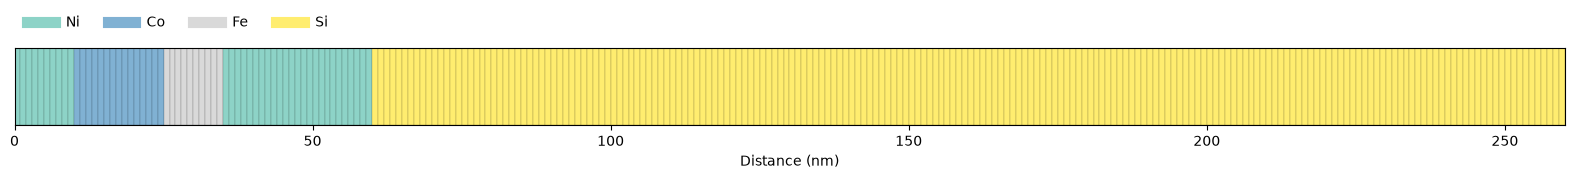

In [8]:
S.visualize()

## Initialize Heat and the Excitation

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [9]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

In [10]:
h.excitation = {
    "fluence": [25] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.15] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}
# temporal and spatial grid
delays = np.r_[-10:10:0.05, 10:200:0.5] * u.ps
_, _, distances = S.get_distances_of_layers()

## Calculate Heat Diffusion for 2-Temperature Model

In [11]:
# enable heat diffusion
h.heat_diffusion = True
# set the boundary conditions
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
# The resulting temperature profile is calculated in one line:

temp_map, delta_temp = h.get_temp_map(delays, 300)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Calculating _heat_diffusion_ for excitation 1:1 ...
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 46.5 % and transmission of 3.9 %.


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.100818 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.063857 s


Elapsed time for _temp_map_: 0.238882 s


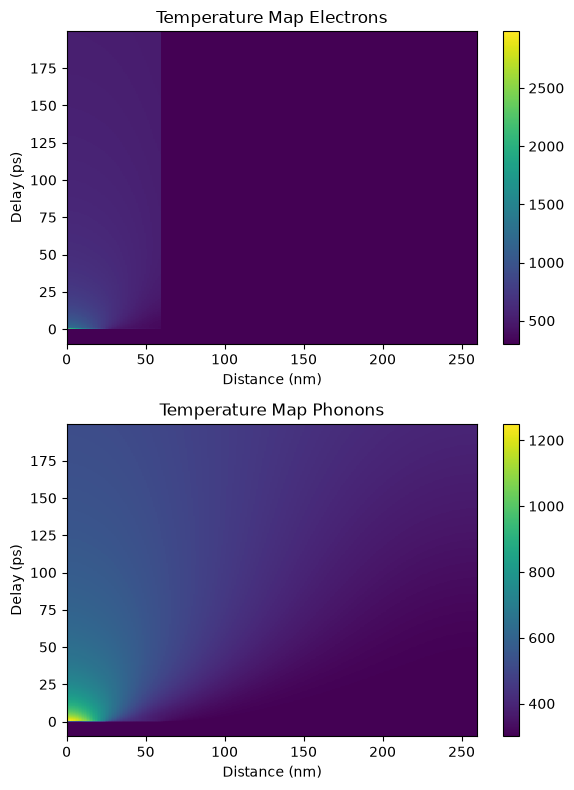

In [12]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 0], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Electrons")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 1], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Phonons")

plt.tight_layout()
plt.show()

## Landau-Lifshitz-Bloch Simulations

The {py:class}`LLB <udkm1Dsim.simulations.magnetization.LLB>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can be enabled using the boolean switch `progress_bar`.

In [13]:
llb = ud.LLB(S, True)

llb.save_data = False
llb.disp_messages = True

llb

Landau-Lifshitz-Bloch Magnetization Dynamics simulation properties:

================  =======
       parameter  value
================  =======
    force recalc  True
 cache directory  ./
display messages  True
       save data  False
    progress bar  True
================  =======

This is the current structure for the simulations:

Structure properties:

Name   : NiCoFeNi
Thickness : 260 nm
----
10 times Ni amorphous: 10 nm
15 times Co amorphous: 15 nm
10 times Fe amorphous: 10 nm
25 times Ni amorphous: 25 nm
200 times Si amorphous: 200 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Si amorphous: 1 nm

### Brillouin Function

Internally, the LLB calculates a mean-field magnetization map for the according electron temperatures
$T_e$ at for every layer and for every time step. This is done by solving the *Brillouin* function of each
layer and then mapping the result onto the according spatio-temporal grid, as given by the `temp_map`.

In [14]:
mean_field_mag_map = llb.get_mean_field_mag_map(temp_map[:, :, 0])

Calculating _mean_field_magnetization_map_ ...


Elapsed time for _mean_field_magnetization_map_: 0.488639 s


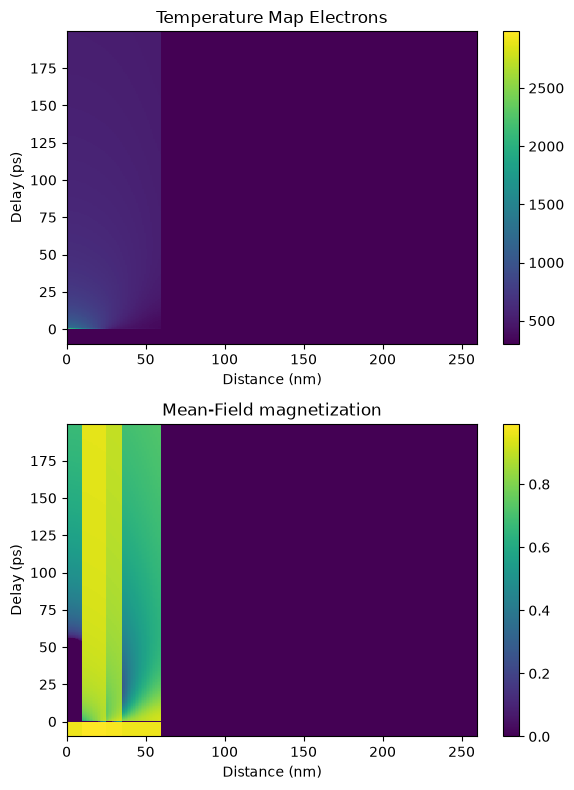

In [15]:
plt.figure(figsize=[6, 8])

plt.subplot(2, 1, 1)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 0], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Electrons")

plt.subplot(2, 1, 2)

plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, mean_field_mag_map, shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Mean-Field magnetization")

plt.tight_layout()

plt.show()

In order to run the actual LLB simulation, an optional initial magnetization `init_mag` as well as an external magnetic field `H_ext` can be provided.
While `H_ext` is provided in cartesian coordinates $[H_x, H_y, H_z]$ in Tesla, the initial magnetization is given in polar coordinates $[r, \phi, \gamma]$ in units of [none, rad, rad], following the definitions shown in the [Getting Started](../../getting_started).

Running the simulation is done by calling the {py:meth}`get_magnetization_map <udkm1Dsim.simulations.magnetization.LLB.get_magnetization_map>` method which requires a `delay` vector as well as the `temp_map`.

:::{note}
The resulting `magnetization_map` is returned in **polar coordinates**.
:::

In [16]:
init_mag = np.array([1.0, (0.0 * u.deg).to("rad").magnitude, (0 * u.deg).to("rad").magnitude])

magnetization_map = llb.get_magnetization_map(
    delays, temp_map=temp_map, init_mag=init_mag, H_ext=np.array([0, 0.05, 1])
)

Calculating _magnetization_map_ ...
Calculating _mean_field_magnetization_map_ ...


Elapsed time for _mean_field_magnetization_map_: 0.485182 s


0it [00:00, ?it/s]

Elapsed time for _LLB_: 0.595325 s
Elapsed time for _magnetization_map_: 0.595440 s


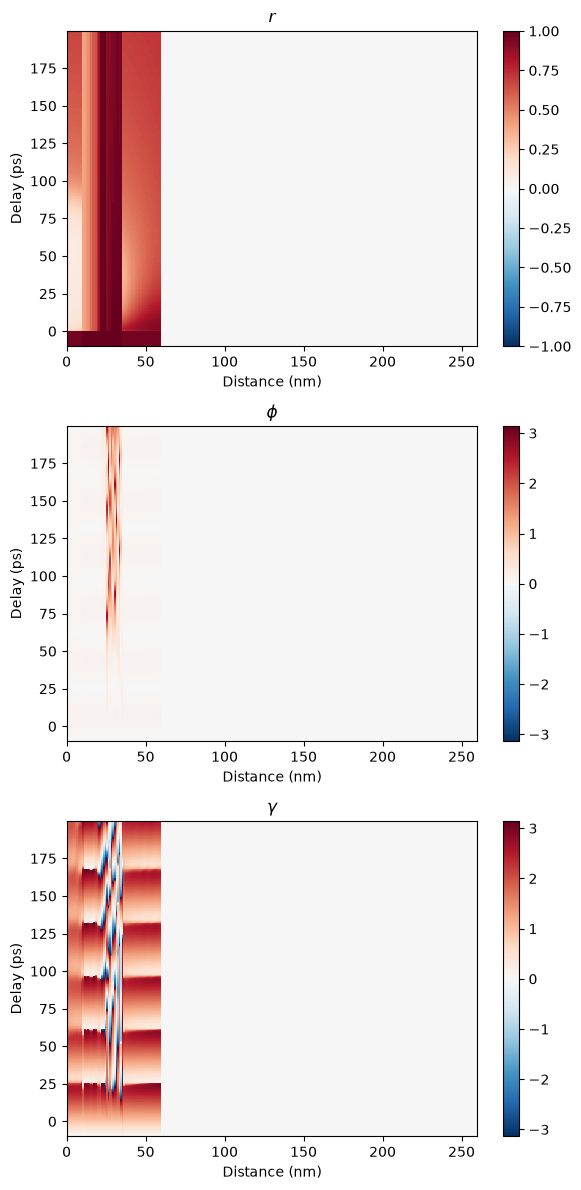

In [17]:
plt.figure(figsize=[6, 12])
plt.subplot(3, 1, 1)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map[:, :, 0],
    shading="auto",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("$r$")

plt.subplot(3, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map[:, :, 1],
    shading="auto",
    cmap="RdBu_r",
    vmin=-3.14,
    vmax=3.14,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title(r"$\phi$")

plt.subplot(3, 1, 3)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map[:, :, 2],
    shading="auto",
    cmap="RdBu_r",
    vmin=-3.14,
    vmax=3.14,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title(r"$\gamma$")

plt.tight_layout()
plt.show()

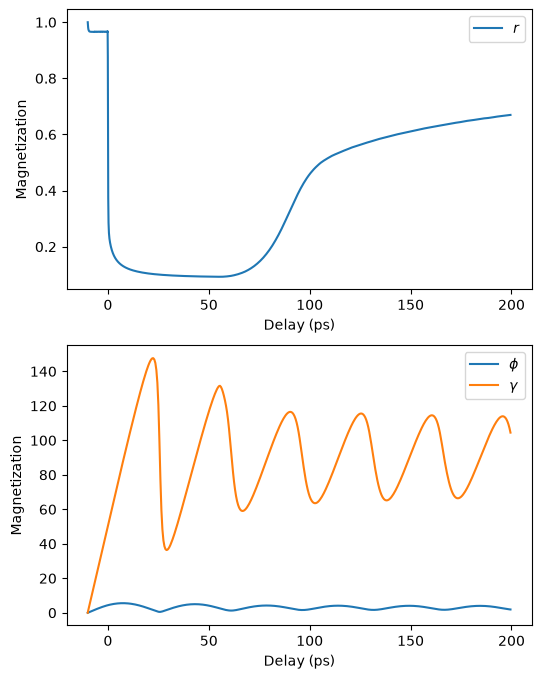

In [18]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(delays, np.mean(magnetization_map[:, 0:10, 0], axis=1), label=r"$r$")
plt.legend()
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.subplot(2, 1, 2)
plt.plot(
    delays, (np.mean(magnetization_map[:, 0:10, 1], axis=1) * u.rad).to("deg"), label=r"$\phi$"
)
plt.plot(
    delays, (np.mean(magnetization_map[:, 0:10, 2], axis=1) * u.rad).to("deg"), label=r"$\gamma$"
)
plt.legend()
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.show()

The {py:mod}`helpers <udkm1Dsim.helpers>` modules provides functions to convert the result also into cartesian coordinates:

In [19]:
magnetization_map_xyz = ud.helpers.convert_polar_to_cartesian(magnetization_map)

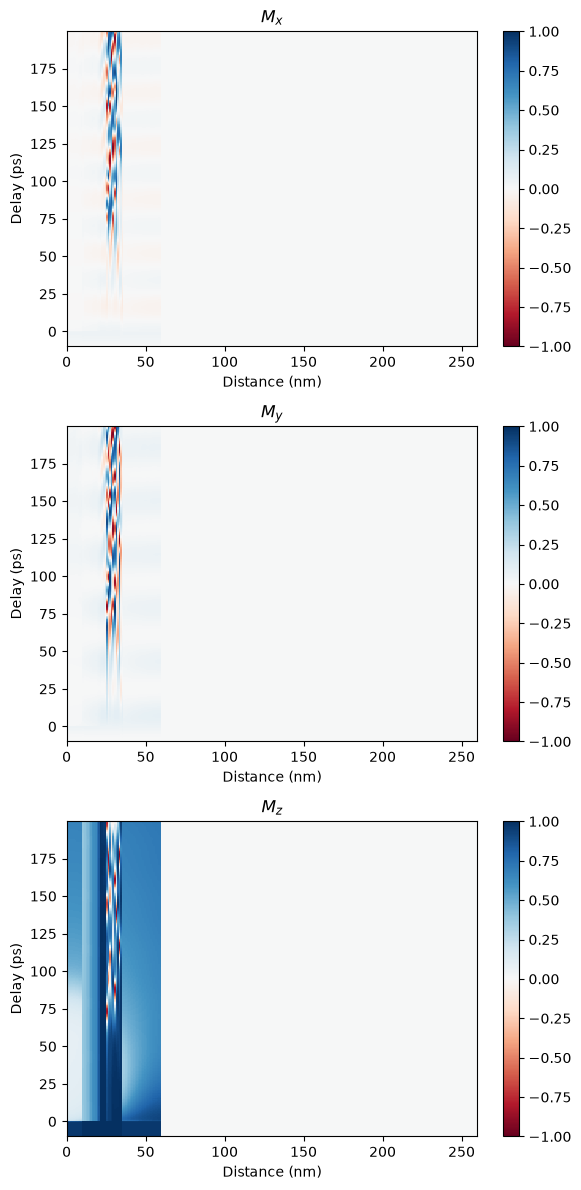

In [20]:
plt.figure(figsize=[6, 12])
plt.subplot(3, 1, 1)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map_xyz[:, :, 0],
    shading="auto",
    cmap="RdBu",
    vmin=-1,
    vmax=1,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("$M_x$")

plt.subplot(3, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map_xyz[:, :, 1],
    shading="auto",
    cmap="RdBu",
    vmin=-1,
    vmax=1,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("$M_y$")

plt.subplot(3, 1, 3)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    magnetization_map_xyz[:, :, 2],
    shading="auto",
    cmap="RdBu",
    vmin=-1,
    vmax=1,
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("$M_z$")

plt.tight_layout()
plt.show()

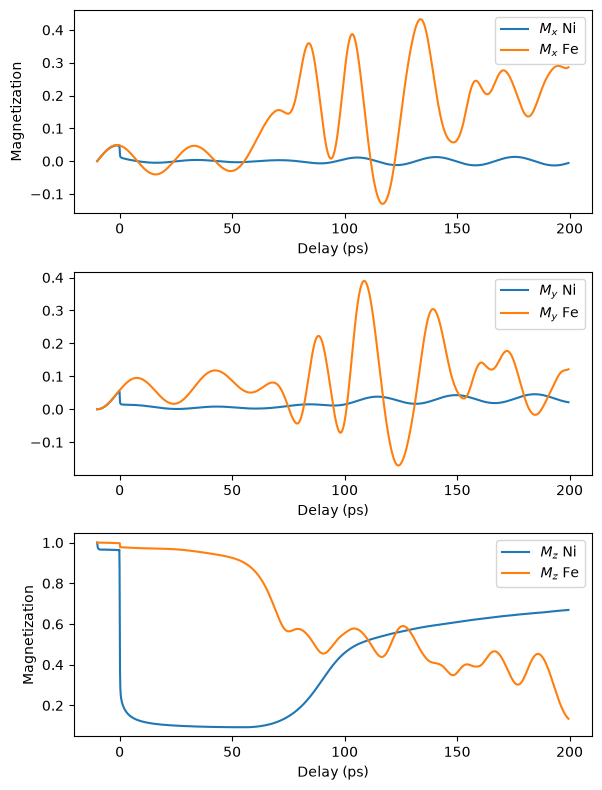

In [21]:
plt.figure(figsize=[6, 8])
plt.subplot(3, 1, 1)
plt.plot(delays, np.mean(magnetization_map_xyz[:, 0:10, 0], axis=1), label=r"$M_x$ Ni")
plt.plot(delays, np.mean(magnetization_map_xyz[:, 25:35, 0], axis=1), label=r"$M_x$ Fe")
plt.legend()
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.subplot(3, 1, 2)
plt.plot(delays, np.mean(magnetization_map_xyz[:, 0:10, 1], axis=1), label=r"$M_y$ Ni")
plt.plot(delays, np.mean(magnetization_map_xyz[:, 25:35, 1], axis=1), label=r"$M_y$ Fe")
plt.xlabel("Delay (ps)")
plt.legend()
plt.subplot(3, 1, 3)
plt.plot(delays, np.mean(magnetization_map_xyz[:, 0:10, 2], axis=1), label=r"$M_z$ Ni")
plt.plot(delays, np.mean(magnetization_map_xyz[:, 25:35, 2], axis=1), label=r"$M_z$ Fe")
plt.legend()
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.tight_layout()
plt.show()

In both subplots it is obvious that the magnetization already starts to change before the actual laser excitation raises the electronic temperatures.
This is because of the misalignment of the initial magnetization and the external magnetic field.
To avoid this, the steady-state solution of the layer magnetization must be found first and used as `init_mag` for the actual transient simulations.